# 02 · Unsupervised Experimental Archetypes & Clustering

Here we combine **TF-IDF + TruncatedSVD** text representations of each report's extracted findings, project title, and hypothesis with encoded experimental protocol features (`celestial_body`, `regolith_simulant`, `crop_guild`, `amendment_categories`). We sweep `k = 2..10` clusters, select the optimal `k` via **Silhouette Score**, and project the corpus into 2D using **PCA** and **UMAP**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
COSE_PALETTE = ["#004053", "#0f7f9f", "#3f7d4e", "#5590ad", "#d97706", "#7c3aed", "#be123c"]

ROOT = Path("../..").resolve()
reports = pd.read_parquet(ROOT / "data/processed/reports.parquet")
pdfs = reports[reports["has_pdf"]].copy().reset_index(drop=True)

text_corpus = (
    pdfs["project_title"].fillna("") + " "
    + pdfs["key_hypothesis"].fillna("") + " "
    + pdfs["summary_findings"].fillna("") + " "
    + pdfs["amendment_categories"].fillna("")
).str.strip()

tfidf = TfidfVectorizer(max_features=800, stop_words="english", ngram_range=(1, 2))
X_txt = tfidf.fit_transform(text_corpus)
n_comp = min(20, max(2, X_txt.shape[1] - 1))
X_svd = TruncatedSVD(n_components=n_comp, random_state=42).fit_transform(X_txt)

cat_cols = ["celestial_body", "regolith_simulant", "crop_guild", "track"]
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_cat = ohe.fit_transform(pdfs[cat_cols].fillna("missing"))

X_feat = StandardScaler().fit_transform(np.hstack([X_svd, X_cat]))
print("Clustering matrix shape:", X_feat.shape)

/Users/drb_laptop/Documents/Plant_the_moon/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Clustering matrix shape: (187, 42)


### Silhouette Sweep Across `k = 2..10`
We evaluate K-Means across `k = 2..10` using the Silhouette Score to avoid choosing an arbitrary cluster count.

In [2]:
scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    lbl = km.fit_predict(X_feat)
    scores.append({"k": k, "silhouette": round(float(silhouette_score(X_feat, lbl)), 4)})

score_df = pd.DataFrame(scores)
best_k = int(score_df.loc[score_df["silhouette"].idxmax(), "k"])
print("Silhouette scores:\n", score_df.to_string(index=False))
print(f"Optimal k = {best_k}")

km_best = KMeans(n_clusters=best_k, n_init=30, random_state=42)
pdfs["cluster"] = km_best.fit_predict(X_feat).astype(str)

# 2D PCA and UMAP projections
pca_xy = PCA(n_components=2, random_state=42).fit_transform(X_feat)
umap_xy = umap.UMAP(n_neighbors=15, min_dist=0.15, random_state=42).fit_transform(X_feat)
pdfs["umap_1"], pdfs["umap_2"] = umap_xy[:, 0], umap_xy[:, 1]
pdfs["pca_1"], pdfs["pca_2"] = pca_xy[:, 0], pca_xy[:, 1]

Silhouette scores:
  k  silhouette
 2      0.0678
 3      0.0641
 4      0.0774
 5      0.0793
 6      0.0730
 7      0.0729
 8      0.0701
 9      0.0949
10      0.0835
Optimal k = 9


/Users/drb_laptop/Documents/Plant_the_moon/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/drb_laptop/Documents/Plant_the_moon/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


### Visualizing Archetypes in 2D UMAP Space
We plot the 2D UMAP projection colored first by unsupervised cluster label and second by discrete `celestial_body` (`lunar`, `martian`, `both`), verifying whether clusters reflect genuine experimental paradigms.

/var/folders/h2/6jpmxqlx5974x94vqq1ftzr40000gn/T/ipykernel_73369/2564409336.py:3: UserWarning: 
The palette list has fewer values (7) than needed (9) and will cycle, which may produce an uninterpretable plot.
  sns.scatterplot(


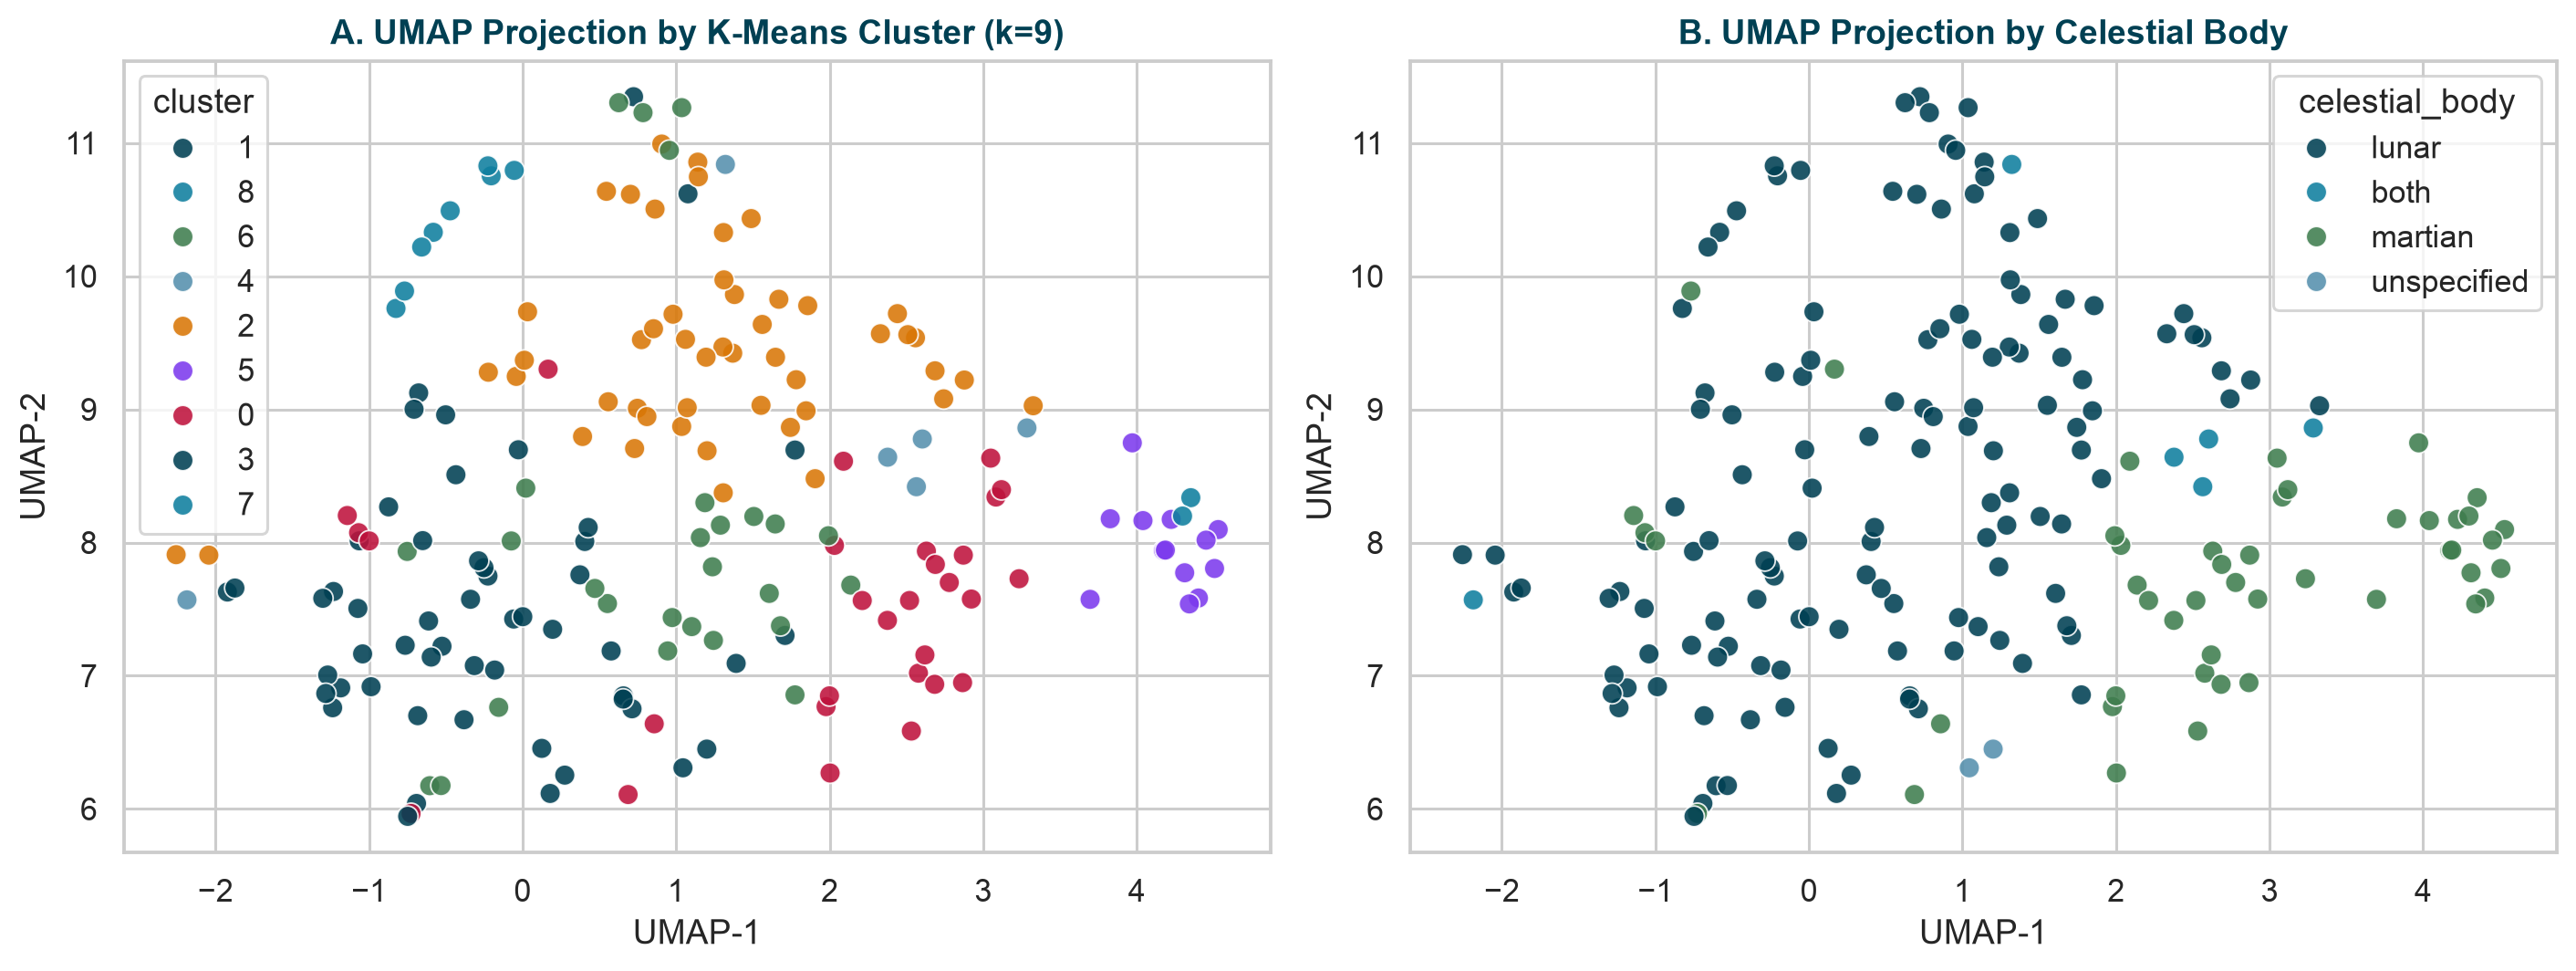

,cluster,n_reports,top_body,top_guild,top_track,pct_reg_ctrl
0,0,29,martian,mixed,main,27.6
1,1,51,lunar,mixed,junior,27.5
2,2,49,lunar,leafy_green,main,42.9
3,3,2,unspecified,unspecified,junior,0.0
4,4,6,both,mixed,junior,66.7
5,5,13,martian,mixed,main,53.8
6,6,27,lunar,legume,junior,40.7
7,7,2,martian,fungi,main,0.0
8,8,8,lunar,fruiting,main,75.0


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.0), dpi=220)

sns.scatterplot(
    data=pdfs, x="umap_1", y="umap_2", hue="cluster",
    palette=COSE_PALETTE[: pdfs["cluster"].nunique()], s=55, alpha=0.88, ax=axes[0]
)
axes[0].set_title(f"A. UMAP Projection by K-Means Cluster (k={best_k})", fontweight="bold", color="#004053")
axes[0].set_xlabel("UMAP-1")
axes[0].set_ylabel("UMAP-2")

sns.scatterplot(
    data=pdfs, x="umap_1", y="umap_2", hue="celestial_body",
    palette=COSE_PALETTE[: pdfs["celestial_body"].nunique()], s=55, alpha=0.88, ax=axes[1]
)
axes[1].set_title("B. UMAP Projection by Celestial Body", fontweight="bold", color="#004053")
axes[1].set_xlabel("UMAP-1")
axes[1].set_ylabel("UMAP-2")

plt.tight_layout()
fig.savefig(ROOT / "manuscript/figures/fig2.png", dpi=220, bbox_inches="tight")
plt.show()

# Cluster characterization table
cluster_profile = (
    pdfs.groupby("cluster")
    .agg(
        n_reports=("report_id", "count"),
        top_body=("celestial_body", lambda s: s.mode().iloc[0]),
        top_guild=("crop_guild", lambda s: s.mode().iloc[0]),
        top_track=("track", lambda s: s.mode().iloc[0]),
        pct_reg_ctrl=("has_unamended_regolith_control", lambda s: round(100 * s.mean(), 1)),
    )
    .reset_index()
)
display(cluster_profile)

### Summary (Notebook 02)
1. Combining semantic text embeddings (`TF-IDF + SVD`) with experimental design metadata separates the 187 PDF reports into coherent, interpretable experimental clusters driven primarily by **celestial target** (`lunar` vs. `martian`), **division track** (`main` vs. `junior`), and **crop guild / amendment paradigm**.
2. These cluster profiles reveal systematic differences in control usage (`pct_reg_ctrl`) across research archetypes, informing stratified/grouped modeling in Notebook 03.